In [2]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\SAMRIDDHI\OneDrive\Desktop\flare\venv\Scripts\python.exe
3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


In [3]:
import sys
print("Python:", sys.executable)

import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Success!")

Python: c:\Users\SAMRIDDHI\OneDrive\Desktop\flare\venv\Scripts\python.exe
NumPy: 2.4.6
Pandas: 3.1.0
Success!


In [4]:
import numpy as np
import pandas as pd

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

print("Both libraries imported successfully!")

NumPy version: 2.4.6
Pandas version: 3.1.0
Both libraries imported successfully!


# SWAN-SF Dataset Exploration

All five partitions are scanned once (cell below), keeping only summaries and small samples so the ~1.8 GB dataset never sits in memory at once. The analysis is split into four parts:

1. **Data quality checks** – missing values, duplicates, invalid entries, feature ranges across partitions
2. **Class imbalance** – samples per partition and exact occurrences of each flare class
3. **Temporal coverage** – sequence lengths, gaps and time span per active region and partition
4. **Feature visualization** – distributions of the 24 SHARP parameters, outliers and target counts

Each CSV is one active region (file name = HARP number) sampled every 12 minutes. The `BFLARE`…`XFLARE` columns count flares of that GOES class occurring at that time step.

## Setup: scan all partitions

In [5]:
import glob, hashlib, io, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = '../data/raw/SWAN'
PARTITIONS = sorted(d for d in os.listdir(DATA_DIR) if d.startswith('partition'))
CADENCE = pd.Timedelta(minutes=12)

# The 24 SHARP magnetic-field parameters used as model inputs
FEATURES = ['TOTUSJH', 'TOTBSQ', 'TOTPOT', 'TOTUSJZ', 'ABSNJZH', 'SAVNCPP', 'USFLUX', 'TOTFZ',
            'MEANPOT', 'EPSZ', 'MEANSHR', 'SHRGT45', 'MEANGAM', 'MEANGBT', 'MEANGBZ', 'MEANGBH',
            'MEANJZH', 'TOTFY', 'MEANJZD', 'MEANALP', 'TOTFX', 'EPSY', 'EPSX', 'R_VALUE']

CLASSES = ['B', 'C', 'M', 'X']                     # GOES classes, weakest to strongest
FLARE_COLS = [f'{c}FLARE' for c in CLASSES]
HORIZON = pd.Timedelta(hours=24)                   # forecast window used for row labels
SAMPLE_PER_PARTITION = 20_000                      # uniform sample for distribution plots
SAMPLE_PER_CLASS = 5_000                           # per-class sample for class-conditional plots

# Flare-count column -> its JSON label column ('None' when there is no flare)
FLARE_LABEL_PAIRS = {f'{c}FLARE': f'{c}FLARE_LABEL' for c in CLASSES}
FLARE_LABEL_PAIRS |= {f'{c}FLARE_LOC': f'{c}FLARE_LABEL_LOC' for c in CLASSES}
LABEL_COLS = list(FLARE_LABEL_PAIRS.values())
BOOL_COLS = ['SPEI', 'IS_TMFI']

# Physically valid ranges. Signed features (TOTFX/Y/Z, EPSX/Y/Z, MEANJZH, MEANJZD, MEANALP)
# have no hard bound and are only checked for finiteness.
NON_NEGATIVE = ['TOTUSJH', 'TOTBSQ', 'TOTPOT', 'TOTUSJZ', 'ABSNJZH', 'SAVNCPP', 'USFLUX', 'MEANPOT',
                'MEANGBT', 'MEANGBZ', 'MEANGBH', 'R_VALUE', 'XR_MAX', 'XR_QUAL', 'QUALITY',
                *FLARE_LABEL_PAIRS]
VALID_RANGES = {c: (0, np.inf) for c in NON_NEGATIVE} | {
    'MEANSHR': (0, 90), 'MEANGAM': (0, 90),          # angles in degrees
    'SHRGT45': (0, 100),                             # percentage of pixels
    'LAT_MIN': (-90, 90), 'LAT_MAX': (-90, 90), 'CRLT_OBS': (-90, 90), 'CRVAL2': (-90, 90),
    'LON_MIN': (-180, 180), 'LON_MAX': (-180, 180),
    'CRVAL1': (0, 360), 'CRLN_OBS': (0, 360),        # Carrington longitude
    'HC_ANGLE': (0, 180),
}

print('Partitions:', PARTITIONS)

Partitions: ['partition1', 'partition2', 'partition3', 'partition4', 'partition5']


In [6]:
def read_sequence(path):
    raw = open(path, 'rb').read()
    # Only empty cells are missing; the string 'None' in label columns means "no flare"
    df = pd.read_csv(io.BytesIO(raw), sep='\t', keep_default_na=False, na_values=[''])
    return df, hashlib.md5(raw).hexdigest()


def is_json(value):
    try:
        json.loads(value)
        return True
    except (TypeError, ValueError):
        return False


def next_flare_class(ts, counts):
    """Strongest flare class occurring in (t, t + HORIZON] for each row, 'none' if no flare follows."""
    t = ts.values
    out = np.full(len(t), 'none', dtype=object)
    for cls in CLASSES:  # weakest first, so stronger classes overwrite
        events = np.sort(t[(counts[f'{cls}FLARE'] > 0).values & ~pd.isna(t)])
        if len(events) == 0:
            continue
        nxt = np.searchsorted(events, t, side='right')  # first event strictly after t
        hit = nxt < len(events)
        hit[hit] = events[nxt[hit]] <= t[hit] + HORIZON.to_timedelta64()
        out[hit] = cls
    return out


expected_cols = None
file_reports = []
part_rows, quality_flags, missing_counts, row_missing, dup_counts, invalid_counts = {}, {}, {}, {}, {}, {}
feature_stats, outlier_counts, event_rows, event_totals, window_counts, monthly_rows = {}, {}, {}, {}, {}, {}
uniform_samples, class_samples = [], []

for part in PARTITIONS:
    frames = []
    for path in sorted(glob.glob(os.path.join(DATA_DIR, part, '*.csv'))):
        df, digest = read_sequence(path)
        if expected_cols is None:
            expected_cols = list(df.columns)
        ts = pd.to_datetime(df['Timestamp'], errors='coerce')
        steps = ts.dropna().diff().dropna()
        counts = df[FLARE_COLS].apply(pd.to_numeric, errors='coerce').fillna(0)
        file_reports.append({
            'partition': part,
            'file': os.path.basename(path),
            'md5': digest,
            'rows': len(df),
            'schema_mismatch': list(df.columns) != expected_cols,
            'bad_timestamps': int(ts.isna().sum()),
            'dup_rows': int(df.duplicated().sum()),
            'dup_timestamps': int(ts.dropna().duplicated().sum()),
            'non_monotonic_steps': int((steps <= pd.Timedelta(0)).sum()),
            'off_cadence_steps': int(((steps > pd.Timedelta(0)) & (steps != CADENCE)).sum()),
            'features_all_missing': int(df[FEATURES].apply(pd.to_numeric, errors='coerce').isna().all().sum()),
            'start': ts.min(),
            'end': ts.max(),
            'max_gap': steps.max() if len(steps) else pd.Timedelta(0),
            **{f'{c}_events': int(counts[f'{c}FLARE'].sum()) for c in CLASSES},
        })
        frames.append(df.assign(_file=os.path.basename(path), _next24=next_flare_class(ts, counts),
                                _month=ts.dt.to_period('M')))

    pdf = pd.concat(frames, ignore_index=True)
    del frames
    data_cols = [c for c in pdf.columns if not c.startswith('_')]
    num_cols = [c for c in data_cols if c not in ['Timestamp', *LABEL_COLS, *BOOL_COLS]]
    num = pdf[num_cols].apply(pd.to_numeric, errors='coerce')
    part_rows[part] = len(pdf)
    quality_flags[part] = int((num['QUALITY'].fillna(0) != 0).sum())

    # --- Missing values ---
    missing_counts[part] = pdf[data_cols].isna().sum()
    n_missing = num[FEATURES].isna().sum(axis=1)
    row_missing[part] = {
        'complete rows': int((n_missing == 0).sum()),
        'rows with some features missing': int(((n_missing > 0) & (n_missing < len(FEATURES))).sum()),
        'rows with all features missing': int((n_missing == len(FEATURES)).sum()),
    }

    # --- Duplicates ---
    within_file = int(pdf.duplicated(subset=data_cols + ['_file']).sum())
    non_empty = num.loc[n_missing < len(FEATURES), FEATURES]
    dup_counts[part] = {
        'identical rows within a file': within_file,
        'identical rows across files': int(pdf.duplicated(subset=data_cols).sum()) - within_file,
        'repeated timestamp within a file': int(pdf.duplicated(subset=['_file', 'Timestamp']).sum()),
        'repeated 24-feature vector (any file/time)': int(non_empty.duplicated().sum()),
    }

    # --- Invalid entries ---
    inv = {}
    for c in num_cols:
        inv[f'{c}: non-numeric'] = int((num[c].isna() & pdf[c].notna()).sum())
        inv[f'{c}: infinite'] = int(np.isinf(num[c]).sum())
    for c, (lo, hi) in VALID_RANGES.items():
        if c in num:
            inv[f'{c}: outside [{lo}, {hi}]'] = int(((num[c] < lo) | (num[c] > hi)).sum())
    inv['LAT_MIN > LAT_MAX'] = int((num['LAT_MIN'] > num['LAT_MAX']).sum())
    inv['LON_MIN > LON_MAX'] = int((num['LON_MIN'] > num['LON_MAX']).sum())
    for count_col, label_col in FLARE_LABEL_PAIRS.items():
        counts = num[count_col]
        inv[f'{count_col}: non-integer count'] = int((counts.notna() & (counts % 1 != 0)).sum())
        labels = pdf[label_col]
        has_label = labels.notna() & (labels != 'None')
        inv[f'{label_col}: malformed JSON'] = sum(not is_json(v) for v in labels[has_label])
        inv[f'{label_col}: disagrees with {count_col} > 0'] = int((has_label != counts.gt(0)).sum())
    for c in BOOL_COLS:
        inv[f'{c}: not True/False'] = int((pdf[c].notna() & ~pdf[c].isin([True, False, 'True', 'False'])).sum())
    invalid_counts[part] = inv

    # --- Feature ranges and outliers (beyond 3 x IQR from the quartiles) ---
    feature_stats[part] = num[FEATURES].describe(percentiles=[0.01, 0.5, 0.99]).T
    q1, q3 = num[FEATURES].quantile(0.25), num[FEATURES].quantile(0.75)
    outlier_counts[part] = ((num[FEATURES] < q1 - 3 * (q3 - q1)) | (num[FEATURES] > q3 + 3 * (q3 - q1))).sum()

    # --- Class imbalance ---
    event_rows[part] = (num[FLARE_COLS] > 0).sum()
    event_totals[part] = num[FLARE_COLS].sum()
    window_counts[part] = pdf['_next24'].value_counts()

    # --- Temporal coverage ---
    monthly_rows[part] = pdf['_month'].value_counts()

    # --- Samples for plots (complete rows only) ---
    complete = num.loc[n_missing == 0, FEATURES].assign(partition=part, next24=pdf.loc[n_missing == 0, '_next24'])
    uniform_samples.append(complete.sample(min(SAMPLE_PER_PARTITION, len(complete)), random_state=0))
    class_samples.append(complete.sample(frac=1, random_state=0).groupby('next24').head(SAMPLE_PER_CLASS))

    print(f'{part}: {pdf._file.nunique():>5} files, {len(pdf):>9,} rows')
    del pdf, num, non_empty, complete

files = pd.DataFrame(file_reports)
rows_per_part = pd.Series(part_rows)
uniform_sample = pd.concat(uniform_samples, ignore_index=True)
class_sample = pd.concat(class_samples, ignore_index=True)
print(f'\nTotal: {len(files):,} files, {rows_per_part.sum():,} rows, {len(expected_cols)} columns')

partition1:   805 files,   585,047 rows
partition2:  1045 files,   756,600 rows
partition3:   474 files,   336,575 rows
partition4:   565 files,   407,795 rows
partition5:  1209 files,   793,641 rows

Total: 4,098 files, 2,879,658 rows, 55 columns


## 1. Data Quality Checks

### 1.1 Missing values

34 of 55 columns contain missing values
Missing cells overall: 8,510,532 (5.37% of all cells)

Row-level completeness of the 24 features:


rows                                   \
                                partition1 partition2 partition3 partition4   
complete rows                       538761     662770     307369     375126   
rows with some features missing       2835      24095       1972       2490   
rows with all features missing       43451      69735      27234      30179   

                                                    %                        \
                                partition5 partition1 partition2 partition3   
complete rows                       725927      92.09      87.60      91.32   
rows with some features missing       4020       0.48       3.18       0.59   
rows with all features missing       63694       7.43       9.22       8.09   

                                                       
                                partition4 partition5  
complete rows                        91.99      91.47  
rows with some features missing       0.61       0.51  
rows with all features missing        7.40       8.03

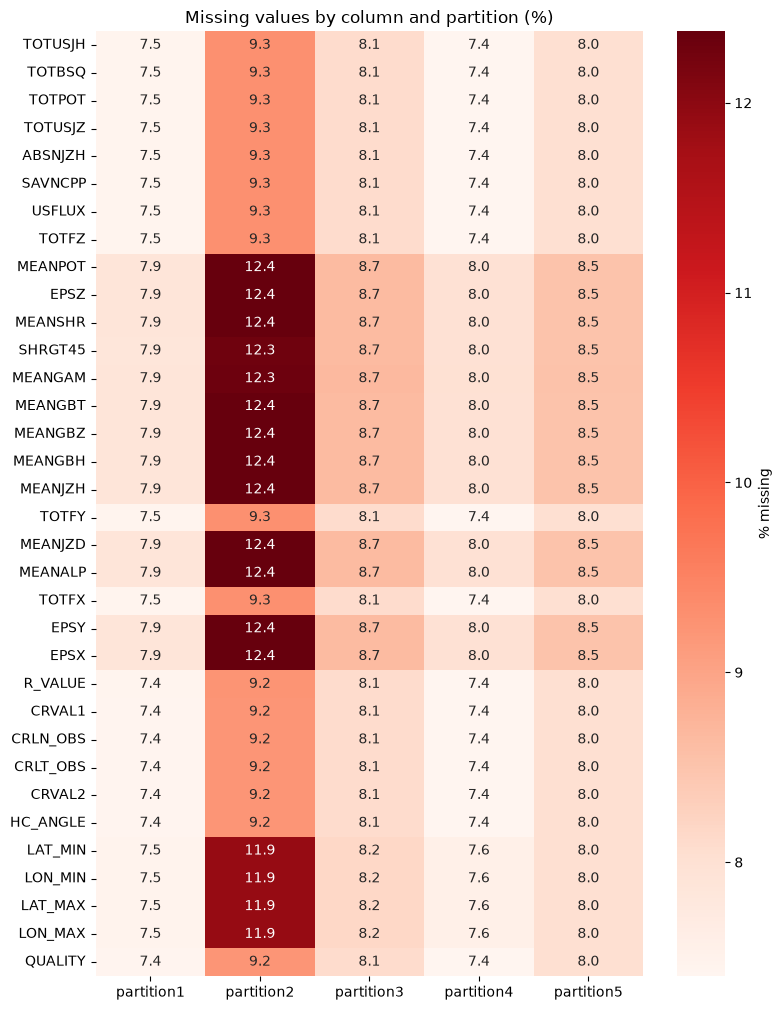

In [7]:
missing_df = pd.DataFrame(missing_counts)
missing_pct = missing_df.div(rows_per_part, axis=1) * 100
cols_with_missing = missing_df.index[missing_df.sum(axis=1) > 0]

print(f'{len(cols_with_missing)} of {len(missing_df)} columns contain missing values')
print(f'Missing cells overall: {missing_df.values.sum():,} '
      f'({missing_df.values.sum() / (rows_per_part.sum() * len(missing_df)):.2%} of all cells)\n')

print('Row-level completeness of the 24 features:')
row_missing_df = pd.DataFrame(row_missing)
display(pd.concat({'rows': row_missing_df, '%': (row_missing_df / rows_per_part * 100).round(2)}, axis=1))

if len(cols_with_missing):
    fig, ax = plt.subplots(figsize=(8, max(4, 0.3 * len(cols_with_missing))))
    sns.heatmap(missing_pct.loc[cols_with_missing], annot=True, fmt='.1f', cmap='Reds',
                cbar_kws={'label': '% missing'}, ax=ax)
    ax.set_title('Missing values by column and partition (%)')
    plt.tight_layout()
    plt.show()

In [8]:
# Sequences where a feature is missing in every row (useless for that active region)
fully_missing = files[files.features_all_missing > 0]
print(f'Sequences with at least one feature missing in every row: {len(fully_missing)}')
display(fully_missing.groupby('partition').size().reindex(PARTITIONS, fill_value=0).rename('sequences'))

Sequences with at least one feature missing in every row: 27


partition
partition1     4
partition2     3
partition3     5
partition4     4
partition5    11
Name: sequences, dtype: int64

### 1.2 Duplicates

In [9]:
print('Row-level duplicates per partition:')
display(pd.DataFrame(dup_counts))

dup_files = files[files.duplicated('md5', keep=False)].sort_values('md5')
print(f'\nByte-identical files: {len(dup_files)}')
if len(dup_files):
    display(dup_files[['partition', 'file', 'rows', 'md5']])

# The same active-region file name in more than one partition could leak data between train/test splits
repeated_ar = files[files.duplicated('file', keep=False)].sort_values('file')
print(f'Active-region file names appearing in more than one partition: {repeated_ar.file.nunique()}')
if len(repeated_ar):
    display(repeated_ar[['file', 'partition', 'rows']].head(20))

Row-level duplicates per partition:


,partition1,partition2,partition3,partition4,partition5
identical rows within a file,0,0,0,0,0
identical rows across files,18671,39144,12493,15564,25111
repeated timestamp within a file,0,0,0,0,0
repeated 24-feature vector (any file/time),2028,22804,1611,2071,3367



Byte-identical files: 0
Active-region file names appearing in more than one partition: 0


### 1.3 Invalid entries

In [10]:
invalid_df = pd.DataFrame(invalid_counts)
failing = invalid_df[invalid_df.sum(axis=1) > 0]
print(f'{len(invalid_df) - len(failing)} of {len(invalid_df)} value checks passed in every partition')
if len(failing):
    print('Checks with violations (row counts):')
    display(failing)

timeline = files.groupby('partition')[['schema_mismatch', 'bad_timestamps', 'dup_timestamps',
                                         'non_monotonic_steps', 'off_cadence_steps']].sum()
timeline['files with off-cadence gaps'] = files[files.off_cadence_steps > 0].groupby('partition').size()
print(f'\nSchema and timestamp checks (expected cadence {CADENCE}):')
display(timeline.fillna(0).astype(int))

print('Rows with a non-zero QUALITY flag (HMI frame flagged as degraded; a warning, not invalid):')
display((pd.Series(quality_flags) / rows_per_part * 100).round(2).rename('% of rows'))

140 of 151 value checks passed in every partition
Checks with violations (row counts):


,partition1,partition2,partition3,partition4,partition5
"XR_MAX: outside [0, inf]",3328,9795,3531,5057,2676
"MEANSHR: outside [0, 90]",3,7,2,2,3
"CRVAL1: outside [0, 360]",51528,58162,29615,30764,62703
BFLARE_LABEL: malformed JSON,92,6,1,0,12
CFLARE_LABEL: malformed JSON,16,10,3,4,10
MFLARE_LABEL: malformed JSON,1,0,2,2,0
XFLARE_LABEL: malformed JSON,1,0,0,0,0
BFLARE_LABEL_LOC: malformed JSON,89,6,1,0,10
CFLARE_LABEL_LOC: malformed JSON,15,10,3,4,9
MFLARE_LABEL_LOC: malformed JSON,1,0,2,1,0



Schema and timestamp checks (expected cadence 0 days 00:12:00):


,schema_mismatch,bad_timestamps,dup_timestamps,non_monotonic_steps,off_cadence_steps,files with off-cadence gaps
partition,,,,,,
partition1,0,0,0,0,0,0
partition2,0,0,0,0,0,0
partition3,0,0,0,0,0,0
partition4,0,0,0,0,0,0
partition5,0,0,0,0,0,0


Rows with a non-zero QUALITY flag (HMI frame flagged as degraded; a warning, not invalid):


partition1     5.43
partition2     6.62
partition3     4.63
partition4     4.34
partition5    28.13
Name: % of rows, dtype: float64

### 1.4 Feature ranges across partitions

In [11]:
ranges = pd.concat({p: s[['min', 'max']] for p, s in feature_stats.items()}, axis=1)
with pd.option_context('display.float_format', '{:.3g}'.format, 'display.max_columns', None):
    display(ranges)

# Flag features whose median in some partition falls outside the 1st-99th percentile band of another
medians = pd.DataFrame({p: s['50%'] for p, s in feature_stats.items()})
p01 = pd.DataFrame({p: s['1%'] for p, s in feature_stats.items()})
p99 = pd.DataFrame({p: s['99%'] for p, s in feature_stats.items()})
shifted = [f for f in FEATURES if (medians.loc[f].max() > p99.loc[f].min()) or (medians.loc[f].min() < p01.loc[f].max())]
print('Features with a large shift between partitions:', shifted or 'none')

partition1          partition2          partition3           \
               min      max        min      max        min      max   
TOTUSJH          0 6.33e+03          0 8.95e+03          0 1.15e+04   
TOTBSQ           0 1.05e+11          0 1.35e+11          0 1.43e+11   
TOTPOT           0 8.67e+25          0 1.78e+26          0 8.68e+26   
TOTUSJZ          0 1.99e+14          0 2.83e+14          0 1.63e+14   
ABSNJZH          0 2.58e+03          0 2.49e+03          0 2.98e+03   
SAVNCPP          0 1.01e+14          0 1.05e+14          0 1.09e+14   
USFLUX           0 8.78e+22          0  1.3e+23          0  1.2e+23   
TOTFZ    -3.93e+25  2.2e+24  -5.26e+25 2.82e+24  -5.22e+25 3.77e+24   
MEANPOT       7.89 3.95e+08       5.02 2.02e+09       13.1 3.21e+09   
EPSZ        -0.997    0.999     -0.999        1     -0.995    0.996   
MEANSHR       2.14      162       1.72      165       2.57      136   
SHRGT45          0      100          0      100          0      100   
MEANGAM       8.85     88.9       8.06     89.1       9.85     87.4   
MEANGBT       6.17      655       3.64      319       6.55      288   
MEANGBZ       4.38      572       4.93      686       8.02      751   
MEANGBH       1.88      583       4.74      299       3.19      192   
MEANJZH     -0.239    0.363     -0.246    0.478     -0.235    0.187   
TOTFY    -4.62e+24 9.43e+24   -1.2e+25 4.55e+24  -7.27e+24 4.09e+24   
MEANJZD      -46.8     56.1      -68.7       31      -36.1     27.1   
MEANALP      -26.5     3.88      -11.9     39.5      -50.8     1.65   
TOTFX     -1.1e+25 1.37e+25  -1.72e+25 1.57e+25  -1.53e+25 1.84e+25   
EPSY         -0.48    0.492     -0.493    0.499     -0.488    0.492   
EPSX        -0.484    0.474     -0.497    0.492     -0.482    0.479   
R_VALUE          0      8.8          0     7.59          0     6.67   

        partition4          partition5           
               min      max        min      max  
TOTUSJH          0 3.51e+04          0  7.8e+03  
TOTBSQ           0 2.55e+11          0 9.18e+10  
TOTPOT           0 1.71e+26          0 1.76e+26  
TOTUSJZ          0 9.53e+14          0 1.31e+14  
ABSNJZH          0 2.35e+03          0 4.08e+03  
SAVNCPP          0 7.17e+13          0 1.07e+14  
USFLUX           0 2.08e+23          0 9.69e+22  
TOTFZ    -7.79e+25 1.07e+25  -3.95e+25 3.39e+24  
MEANPOT       2.92 2.62e+08       0.91 9.16e+08  
EPSZ        -0.999    0.975     -0.995    0.998  
MEANSHR       1.24       96      0.856      147  
SHRGT45          0      100          0      100  
MEANGAM       10.2     87.4       9.97     88.3  
MEANGBT       4.66      664       4.19      308  
MEANGBZ       5.87      725       4.08      760  
MEANGBH       1.45      440       4.24      320  
MEANJZH     -0.586    0.292     -0.335    0.267  
TOTFY     -1.7e+25 4.65e+24  -6.51e+24 6.56e+24  
MEANJZD      -44.2     25.3      -38.2     50.5  
MEANALP      -1.31     1.47      -12.1     11.5  
TOTFX    -2.53e+25 2.17e+25  -1.27e+25 1.21e+25  
EPSY        -0.476    0.481     -0.491    0.494  
EPSX        -0.486    0.492     -0.494    0.499  
R_VALUE          0     5.99          0     5.87

Features with a large shift between partitions: none


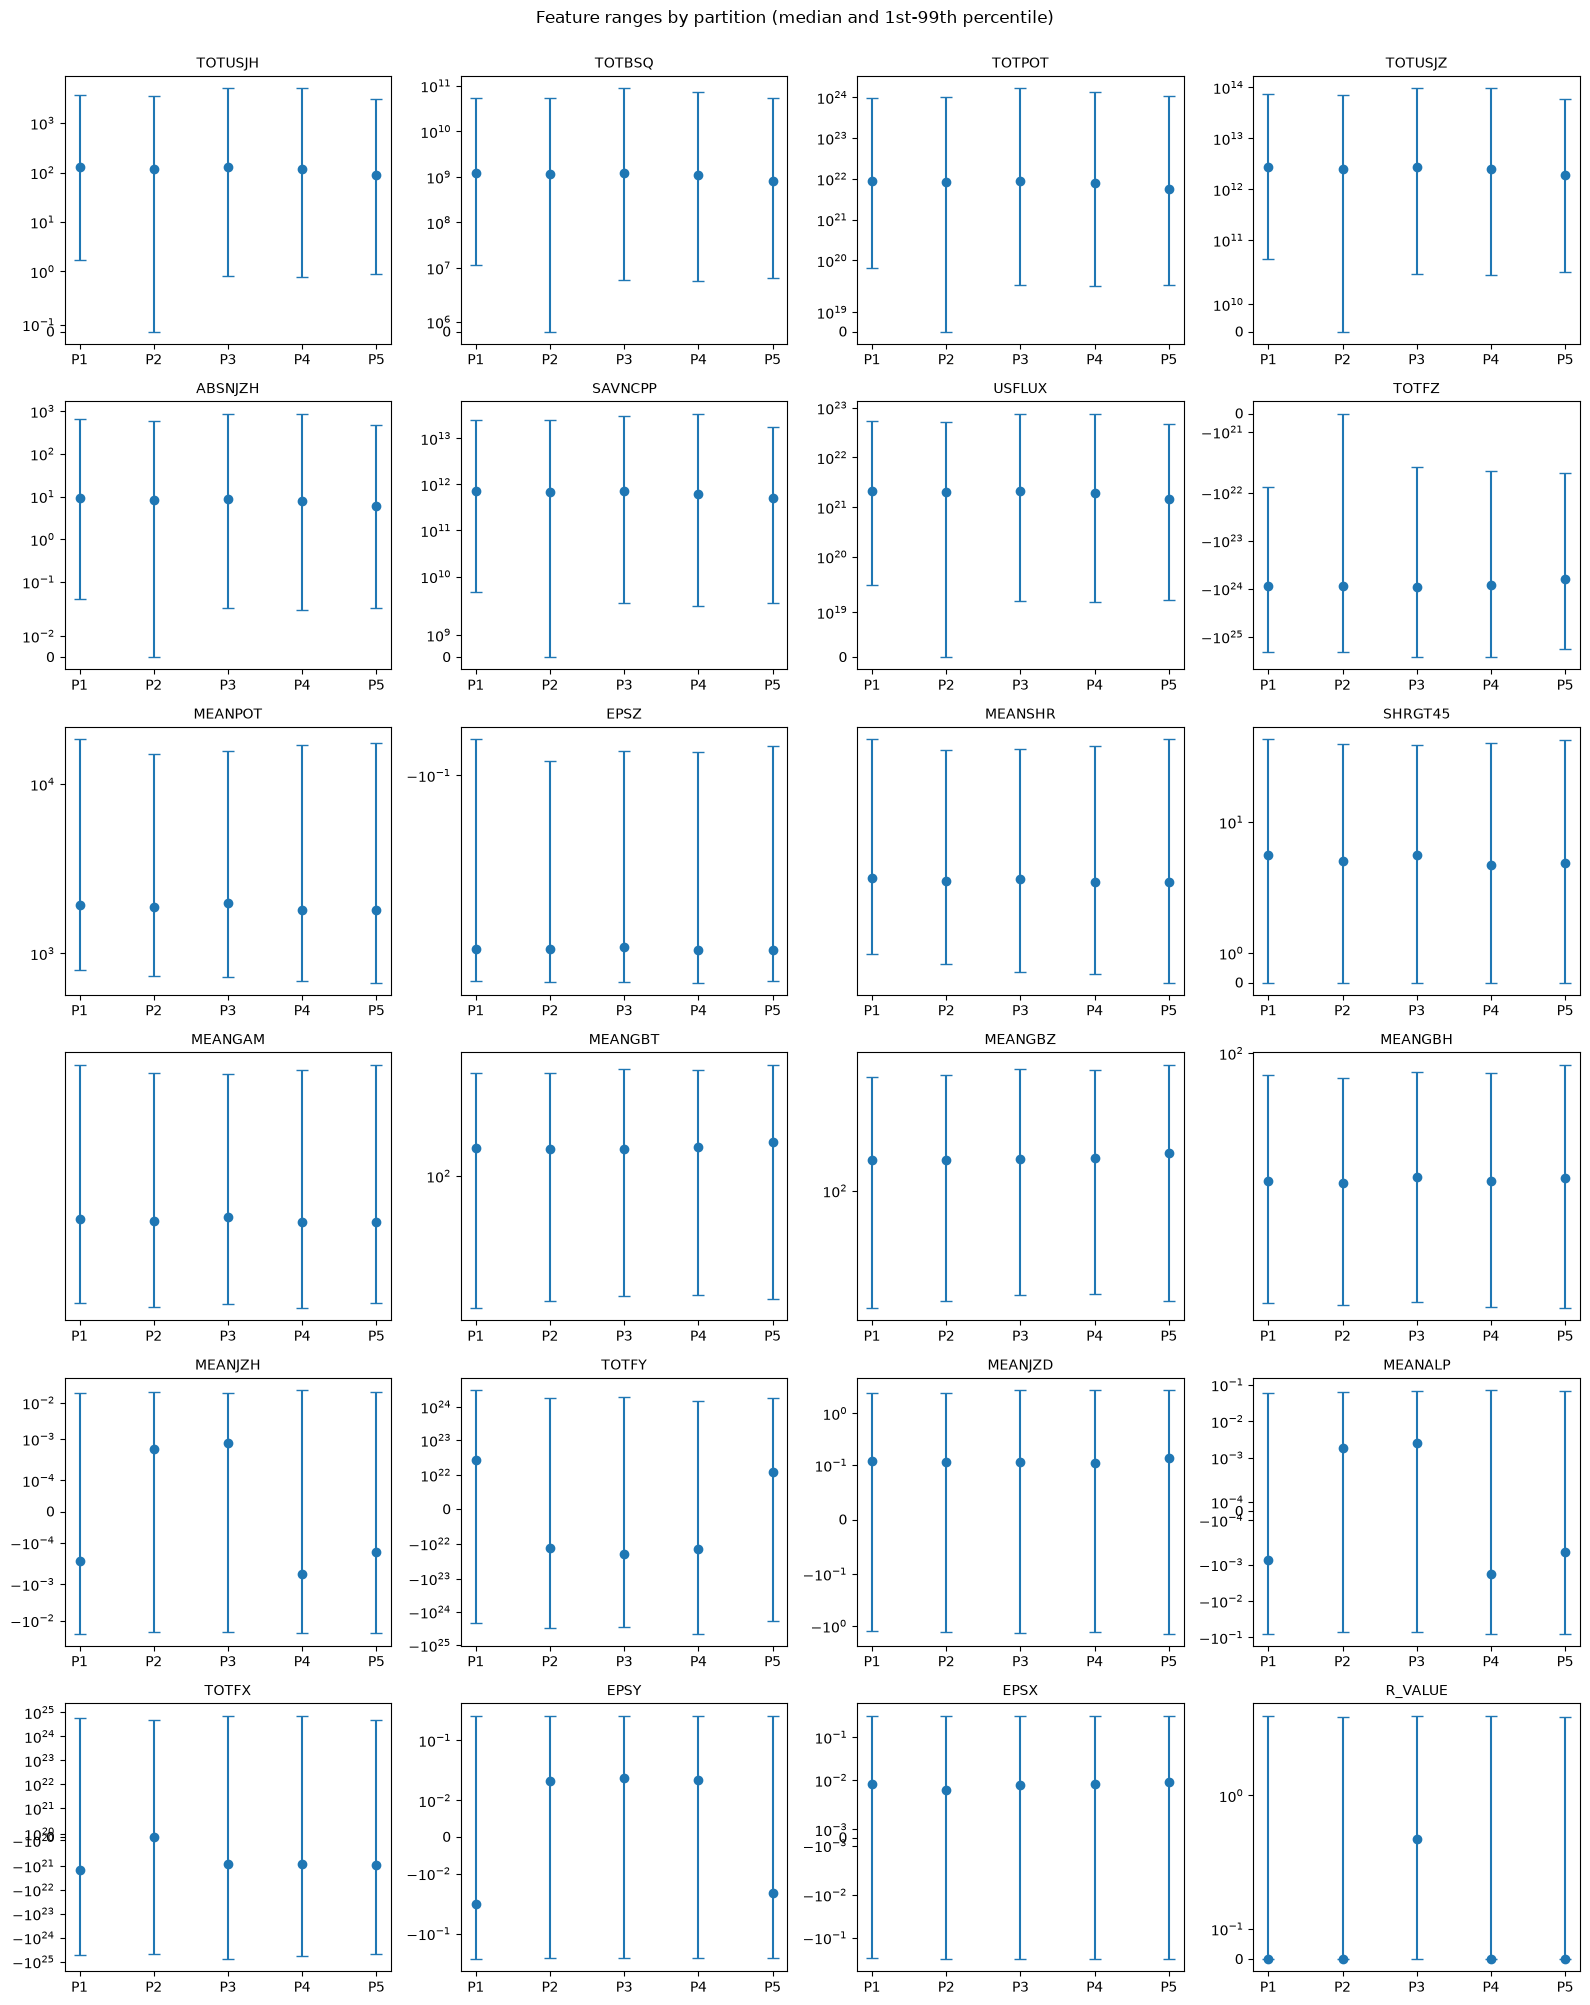

In [12]:
# Median (dot) and 1st-99th percentile range (bar) of each feature per partition.
# symlog keeps both the huge totals (~1e24) and signed features readable on one axis type.
fig, axes = plt.subplots(6, 4, figsize=(16, 20))
x = np.arange(len(PARTITIONS))
for ax, feat in zip(axes.flat, FEATURES):
    lo, med, hi = p01.loc[feat].values, medians.loc[feat].values, p99.loc[feat].values
    ax.errorbar(x, med, yerr=[med - lo, hi - med], fmt='o', capsize=4)
    nonzero = np.abs(np.r_[lo, med, hi])
    nonzero = nonzero[nonzero > 0]
    ax.set_yscale('symlog', linthresh=nonzero.min() if len(nonzero) else 1)
    ax.set_xticks(x, [p.replace('partition', 'P') for p in PARTITIONS])
    ax.set_title(feat, fontsize=10)
fig.suptitle('Feature ranges by partition (median and 1st-99th percentile)', y=1.0)
plt.tight_layout()
plt.show()

## 2. Class Imbalance

Two views of the targets:

* **Flare events** – time steps at which a flare of that class occurs (the raw `*FLARE` columns).
* **24 h forecast label** – each row is labelled with the strongest flare class occurring in the next 24 hours, or `none`. This is how flare-forecasting targets are usually framed, so it is the imbalance a model would actually see.

In [13]:
events = pd.DataFrame(event_rows).T.astype(int)
events.columns = CLASSES
events.loc['total'] = events.sum()
totals = pd.DataFrame(event_totals).T.astype(int)
totals.columns = CLASSES
totals.loc['total'] = totals.sum()
samples = pd.concat([rows_per_part, pd.Series({'total': rows_per_part.sum()})])

print('Total samples (rows) per partition:')
display(samples.rename('rows').to_frame())
print('Flare events per class (number of flares):')
display(totals)
print('Rows at which a flare of each class occurs, and % of all rows:')
with pd.option_context('display.float_format', '{:.4f}'.format):
    display(pd.concat({'rows': events, '% of rows': events.div(samples, axis=0) * 100}, axis=1))

Total samples (rows) per partition:


,rows
partition1,585047
partition2,756600
partition3,336575
partition4,407795
partition5,793641
total,2879658


Flare events per class (number of flares):


,B,C,M,X
partition1,1360,1307,138,13
partition2,991,1875,152,8
partition3,117,1195,143,10
partition4,187,1213,143,13
partition5,2108,1499,132,4
total,4763,7089,708,48


Rows at which a flare of each class occurs, and % of all rows:


rows                % of rows                     
               B     C    M   X         B      C      M      X
partition1  1268  1291  137  12    0.2167 0.2207 0.0234 0.0021
partition2   985  1865  152   8    0.1302 0.2465 0.0201 0.0011
partition3   116  1192  141  10    0.0345 0.3542 0.0419 0.0030
partition4   187  1209  141  13    0.0459 0.2965 0.0346 0.0032
partition5  2096  1489  132   4    0.2641 0.1876 0.0166 0.0005
total       4652  7046  703  47    0.1615 0.2447 0.0244 0.0016

In [14]:
labels = ['none', *CLASSES]
window = pd.DataFrame(window_counts).T.reindex(columns=labels).fillna(0).astype(int)
window.loc['total'] = window.sum()
window_pct = window.div(window.sum(axis=1), axis=0) * 100

print(f'Rows by strongest flare class in the next {HORIZON}:')
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(pd.concat({'rows': window, '%': window_pct}, axis=1))

# Common binary task: >=M-class flare within 24 h vs everything else
mx = window[['M', 'X']].sum(axis=1)
binary = pd.DataFrame({'>=M (positive)': mx, 'negative': window.sum(axis=1) - mx})
binary['imbalance (neg:pos)'] = (binary['negative'] / binary['>=M (positive)']).round(1)
print('Binary >=M-class task:')
display(binary)

Rows by strongest flare class in the next 1 days 00:00:00:


rows                                   %                     \
_next24        none       B       C      M     X   none     B      C     M   
partition1   474331   46701   52905   9794  1316 81.076 7.982  9.043 1.674   
partition2   629726   39427   75787  10843   817 83.231 5.211 10.017 1.433   
partition3   277934    4764   42542  10220  1115 82.577 1.415 12.640 3.036   
partition4   345343    6851   45466   8782  1353 84.685 1.680 11.149 2.154   
partition5   662930   68840   53381   8115   375 83.530 8.674  6.726 1.023   
total       2390264  166583  270081  47754  4976 83.005 5.785  9.379 1.658   

                  
_next24        X  
partition1 0.225  
partition2 0.108  
partition3 0.331  
partition4 0.332  
partition5 0.047  
total      0.173

Binary >=M-class task:


,>=M (positive),negative,imbalance (neg:pos)
partition1,11110,573937,51.7
partition2,11660,744940,63.9
partition3,11335,325240,28.7
partition4,10135,397660,39.2
partition5,8490,785151,92.5
total,52730,2826928,53.6


Active-region sequences by strongest flare they produce:


strongest_class,none,B,C,M,X
partition,,,,,
partition1,595,66,104,32,8
partition2,803,49,143,45,5
partition3,382,4,49,32,7
partition4,458,6,71,24,6
partition5,952,108,117,30,2


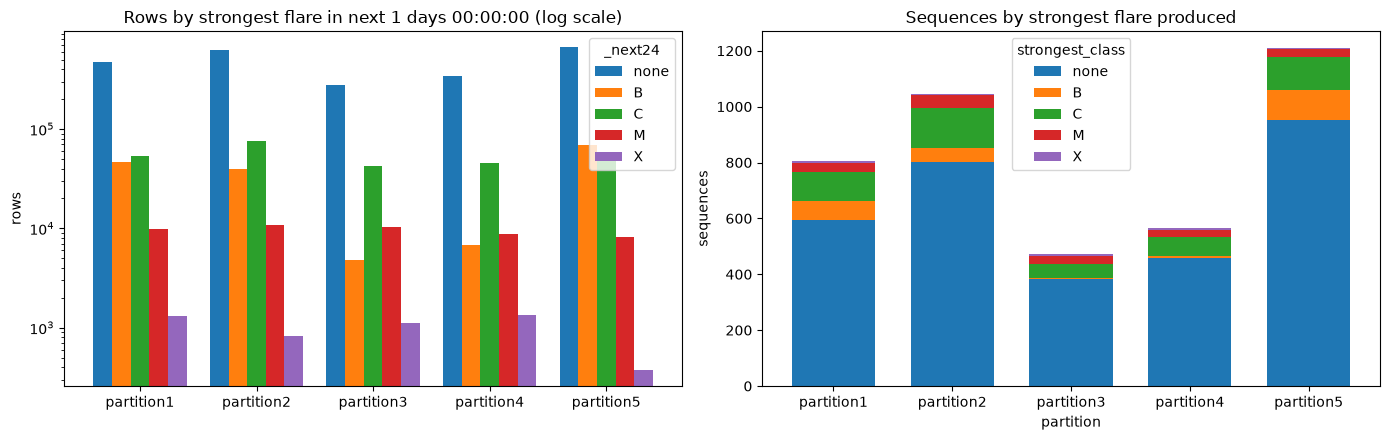

In [15]:
# Sequence level: which active regions produce flares at all
files['strongest_class'] = 'none'
for c in CLASSES:  # weakest first, so stronger classes overwrite
    files.loc[files[f'{c}_events'] > 0, 'strongest_class'] = c
seq_classes = pd.crosstab(files.partition, files.strongest_class).reindex(columns=labels, fill_value=0)
print('Active-region sequences by strongest flare they produce:')
display(seq_classes)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
window.drop(index='total').plot.bar(ax=axes[0], logy=True, width=0.8)
axes[0].set_title(f'Rows by strongest flare in next {HORIZON} (log scale)')
axes[0].set_ylabel('rows')
axes[0].tick_params(axis='x', rotation=0)
seq_classes.plot.bar(ax=axes[1], stacked=True, width=0.7)
axes[1].set_title('Sequences by strongest flare produced')
axes[1].set_ylabel('sequences')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## 3. Temporal Coverage

Each file is one active region, identified by its HARP number (the file name). Sequence length is measured in rows (12-minute steps) and in elapsed time; coverage is the share of the expected 12-minute steps actually present.

In [16]:
files['harp'] = files.file.str.replace('.csv', '', regex=False).astype(int)
files['duration_days'] = (files.end - files.start) / pd.Timedelta(days=1)
files['coverage_%'] = (files.rows / ((files.end - files.start) / CADENCE + 1) * 100).round(1)

print('Sequence length per partition:')
display(files.groupby('partition').agg(
    sequences=('harp', 'size'),
    unique_regions=('harp', 'nunique'),
    min_rows=('rows', 'min'),
    median_rows=('rows', 'median'),
    max_rows=('rows', 'max'),
    median_days=('duration_days', 'median'),
    max_days=('duration_days', 'max'),
    median_coverage_pct=('coverage_%', 'median'),
    longest_gap=('max_gap', 'max'),
))

span = files.groupby('partition').agg(first=('start', 'min'), last=('end', 'max'))
span['span_days'] = (span['last'] - span['first']).dt.days
print('Time span covered by each partition:')
display(span)

# Overlapping time spans matter if partitions are used as separate train/test sets
overlaps = [(a, b) for i, a in enumerate(PARTITIONS) for b in PARTITIONS[i + 1:]
            if span.loc[a, 'first'] < span.loc[b, 'last'] and span.loc[b, 'first'] < span.loc[a, 'last']]
print('Partitions whose time spans overlap:', overlaps or 'none')
print(f'Overall coverage: {files.start.min()} to {files.end.max()}, '
      f'{files.harp.nunique():,} active regions, {files.rows.sum():,} rows')

Sequence length per partition:


,sequences,unique_regions,min_rows,median_rows,max_rows,median_days,max_days,median_coverage_pct,longest_gap
partition,,,,,,,,,
partition1,805,805,5,691.0,1981,5.750000,16.500000,100.0,0 days 00:12:00
partition2,1045,1045,3,677.0,1986,5.633333,16.541667,100.0,0 days 00:12:00
partition3,474,474,5,625.0,2126,5.200000,17.708333,100.0,0 days 00:12:00
partition4,565,565,3,683.0,1932,5.683333,16.091667,100.0,0 days 00:12:00
partition5,1209,1209,1,578.0,1812,4.808333,15.091667,100.0,0 days 00:12:00


Time span covered by each partition:


,first,last,span_days
partition,,,
partition1,2010-05-01 00:00:00,2012-03-16 00:12:00,685
partition2,2012-03-02 23:36:00,2013-10-30 01:12:00,606
partition3,2013-10-16 19:00:00,2014-06-15 17:00:00,241
partition4,2014-06-02 19:24:00,2015-03-20 09:36:00,290
partition5,2015-03-07 10:00:00,2019-01-07 03:00:00,1401


Partitions whose time spans overlap: [('partition1', 'partition2'), ('partition2', 'partition3'), ('partition3', 'partition4'), ('partition4', 'partition5')]
Overall coverage: 2010-05-01 00:00:00 to 2019-01-07 03:00:00, 4,098 active regions, 2,879,658 rows


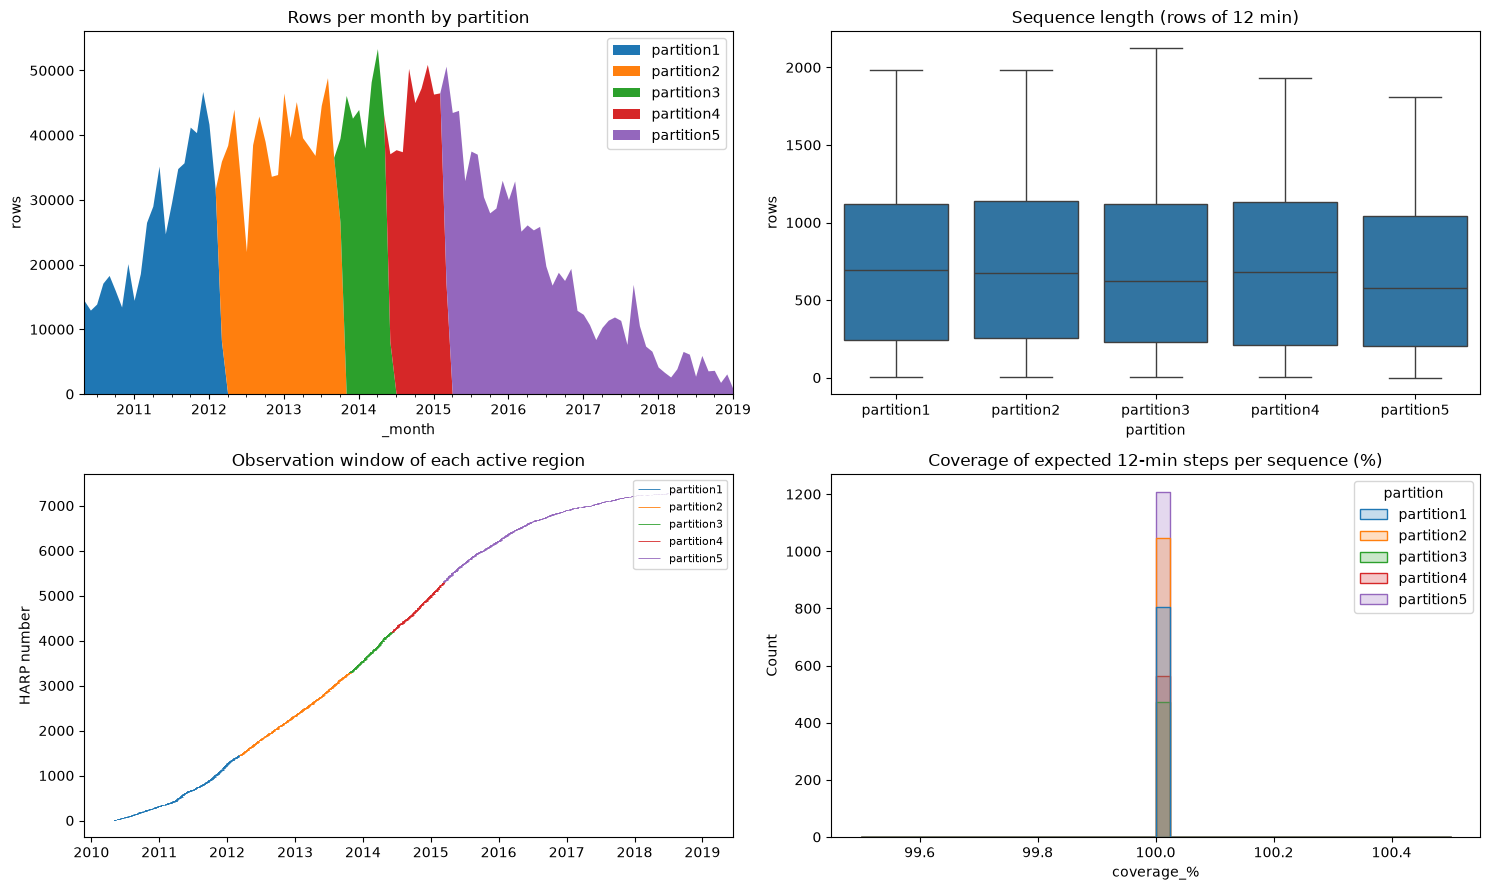

In [17]:
monthly = pd.DataFrame(monthly_rows).fillna(0).sort_index()
monthly.index = monthly.index.to_timestamp()

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
monthly.plot.area(ax=axes[0, 0], linewidth=0)
axes[0, 0].set_title('Rows per month by partition')
axes[0, 0].set_ylabel('rows')

sns.boxplot(data=files, x='partition', y='rows', ax=axes[0, 1])
axes[0, 1].set_title('Sequence length (rows of 12 min)')

for i, (part, grp) in enumerate(files.groupby('partition')):
    axes[1, 0].hlines(grp.harp, grp.start, grp.end, linewidth=0.6, label=part, color=f'C{i}')
axes[1, 0].set_title('Observation window of each active region')
axes[1, 0].set_ylabel('HARP number')
axes[1, 0].legend(fontsize=8)

sns.histplot(data=files, x='coverage_%', hue='partition', bins=40, element='step', ax=axes[1, 1])
axes[1, 1].set_title('Coverage of expected 12-min steps per sequence (%)')
plt.tight_layout()
plt.show()

## 4. Feature Visualization

Distributions use a uniform sample of complete rows from each partition. Heavy-tailed, strictly positive features are shown on a log10 scale; the others on a linear scale clipped to the 0.5–99.5 percentile range so the bulk of the data is visible.

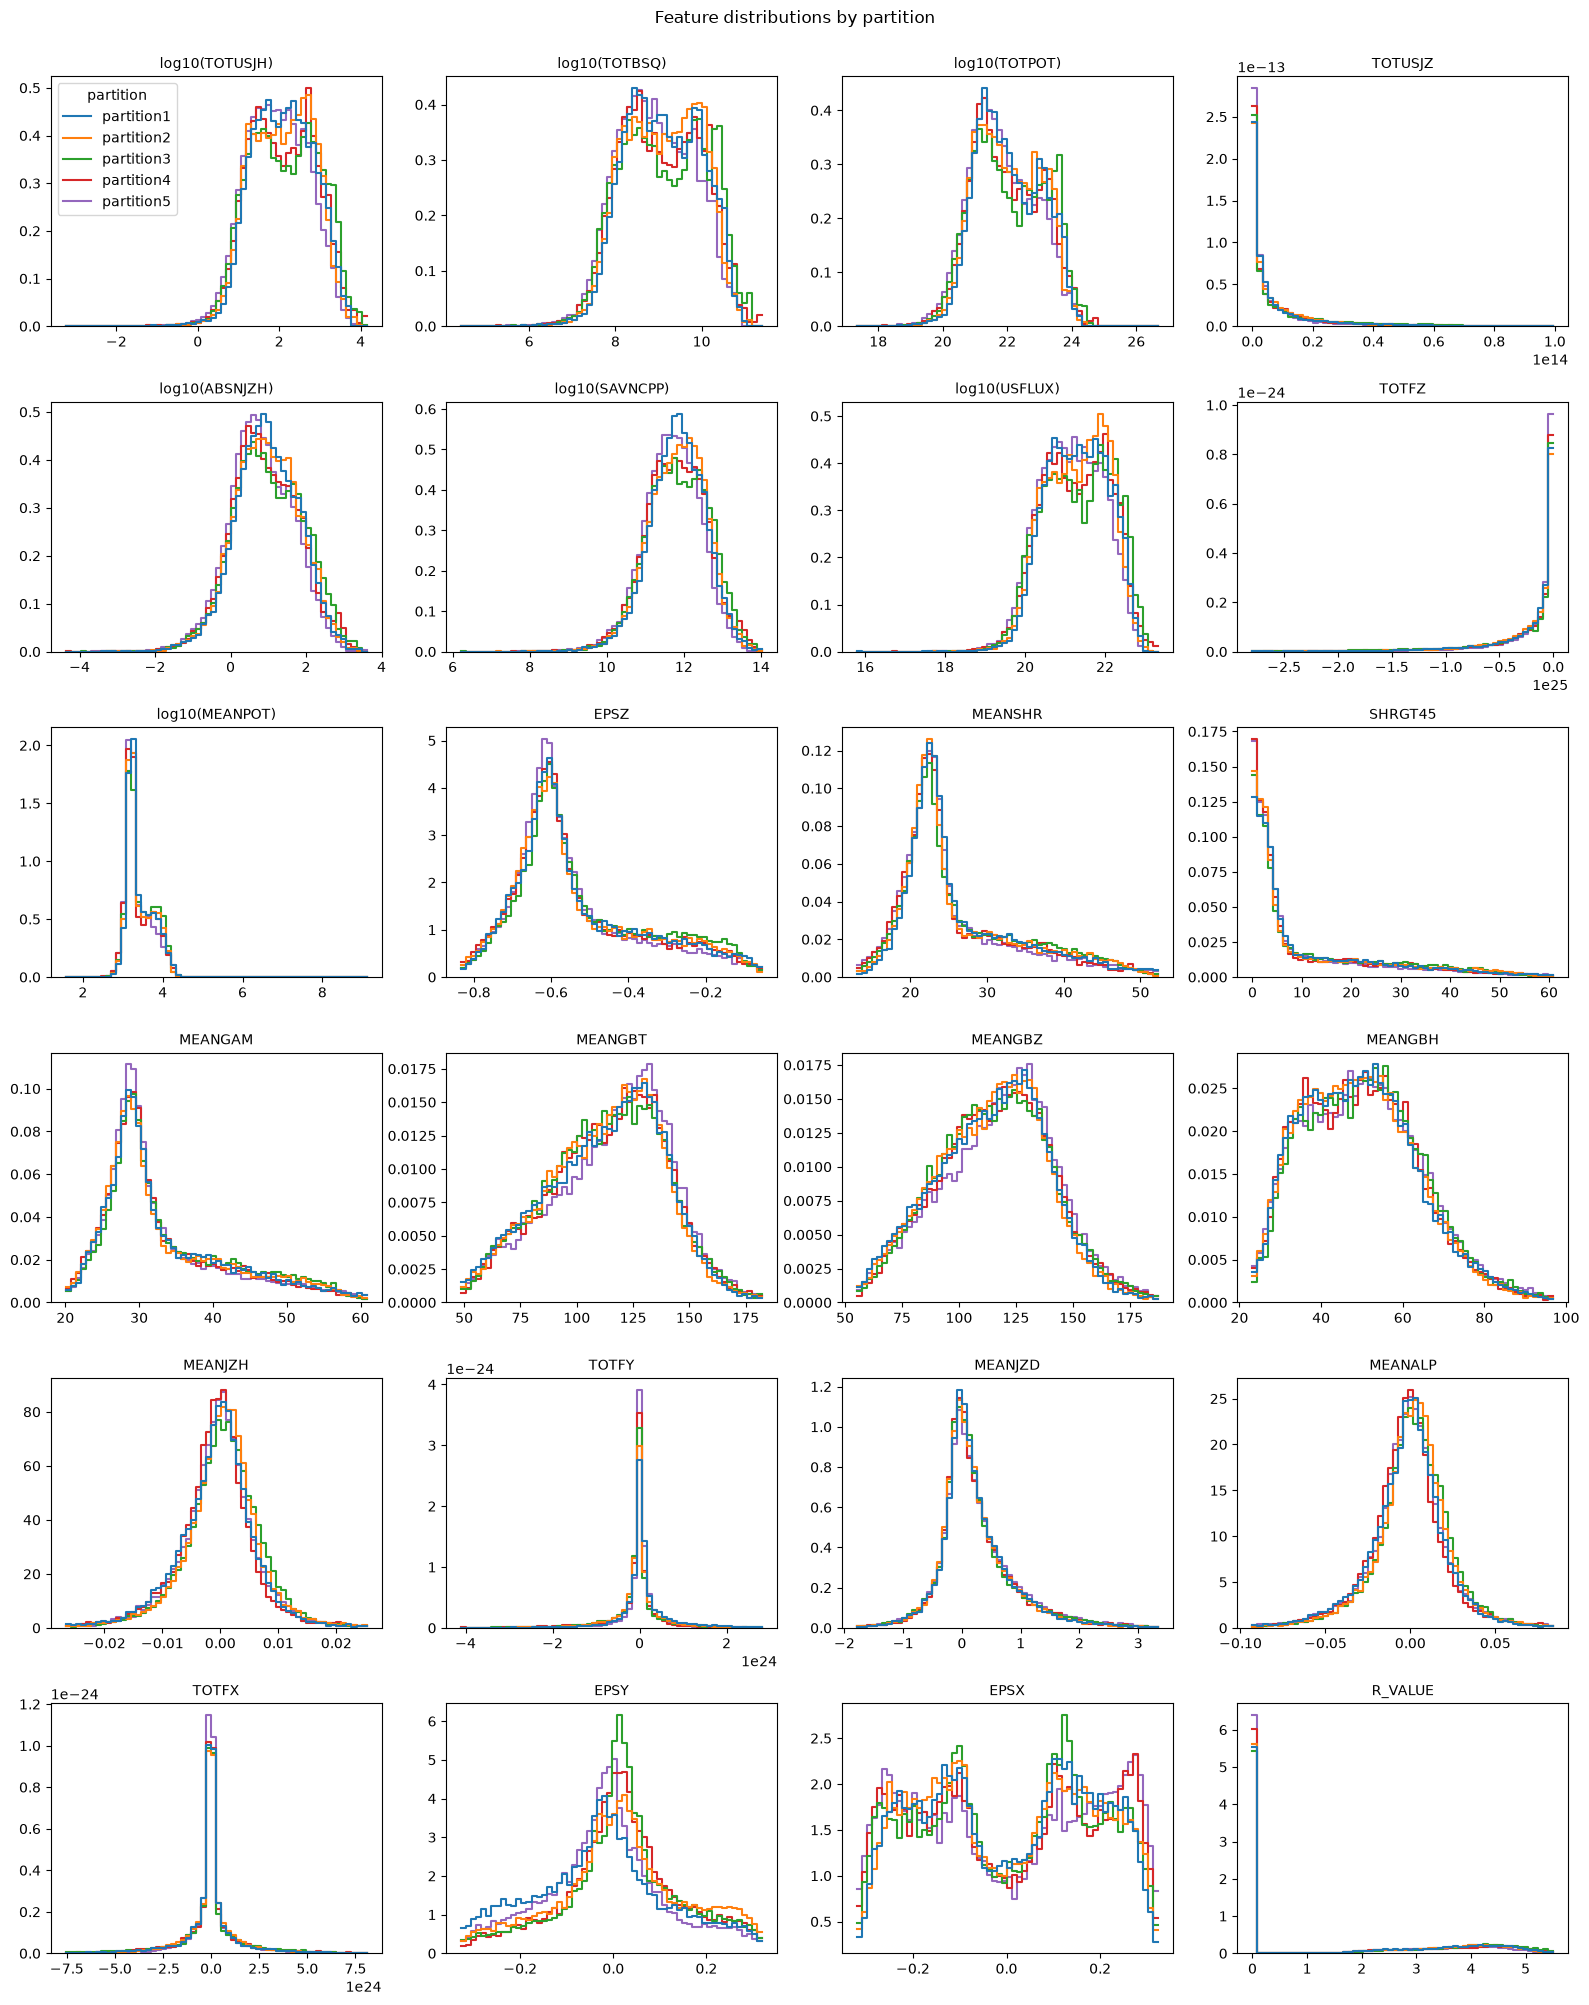

In [18]:
positive = [f for f in FEATURES if (uniform_sample[f] > 0).all()]
log_scale = [f for f in positive if uniform_sample[f].max() / uniform_sample[f].median() > 100]

fig, axes = plt.subplots(6, 4, figsize=(16, 20))
for ax, feat in zip(axes.flat, FEATURES):
    data = uniform_sample[[feat, 'partition']].copy()
    if feat in log_scale:
        data[feat] = np.log10(data[feat])
    else:
        lo, hi = data[feat].quantile([0.005, 0.995])
        data = data[data[feat].between(lo, hi)]
    sns.histplot(data=data, x=feat, hue='partition', bins=60, element='step', fill=False,
                 stat='density', common_norm=False, ax=ax, legend=(feat == FEATURES[0]))
    ax.set_title(f'log10({feat})' if feat in log_scale else feat, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.suptitle('Feature distributions by partition', y=1.0)
plt.tight_layout()
plt.show()

Extreme outliers (beyond 3 x IQR from the quartiles), % of rows:


,partition1,partition2,partition3,partition4,partition5,max
TOTFX,13.90,13.59,17.64,15.95,13.81,17.64
TOTFY,11.71,11.75,13.56,12.79,11.23,13.56
TOTPOT,8.65,7.39,7.95,8.58,10.13,10.13
ABSNJZH,7.37,7.48,7.94,8.09,7.63,8.09
TOTBSQ,5.92,4.43,5.44,6.19,7.01,7.01
SAVNCPP,6.01,4.79,5.90,6.04,5.76,6.04
TOTUSJH,5.52,3.64,5.23,5.34,5.44,5.52
TOTUSJZ,5.48,3.42,5.02,5.17,5.33,5.48
USFLUX,4.60,3.12,4.21,4.45,5.32,5.32
MEANPOT,2.80,1.49,0.74,2.75,5.10,5.10


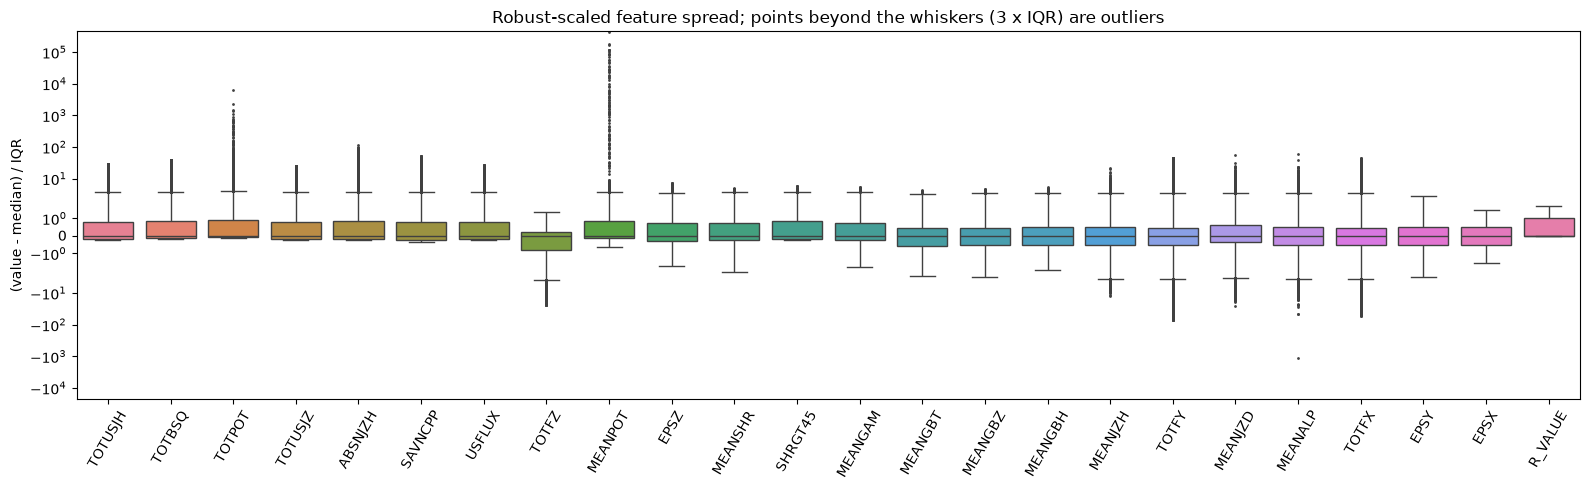

In [19]:
outlier_pct = pd.DataFrame(outlier_counts) / rows_per_part * 100
print('Extreme outliers (beyond 3 x IQR from the quartiles), % of rows:')
with pd.option_context('display.float_format', '{:.2f}'.format):
    display(outlier_pct.assign(max=outlier_pct.max(axis=1)).sort_values('max', ascending=False))

# Robust scaling puts all 24 features on one axis: 0 = median, +-1 = one IQR away
sample = uniform_sample[FEATURES]
robust = (sample - sample.median()) / (sample.quantile(0.75) - sample.quantile(0.25))
fig, ax = plt.subplots(figsize=(16, 5))
sns.boxplot(data=robust, ax=ax, fliersize=1, whis=3)
ax.set_yscale('symlog')
ax.set_ylabel('(value - median) / IQR')
ax.set_title('Robust-scaled feature spread; points beyond the whiskers (3 x IQR) are outliers')
ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()

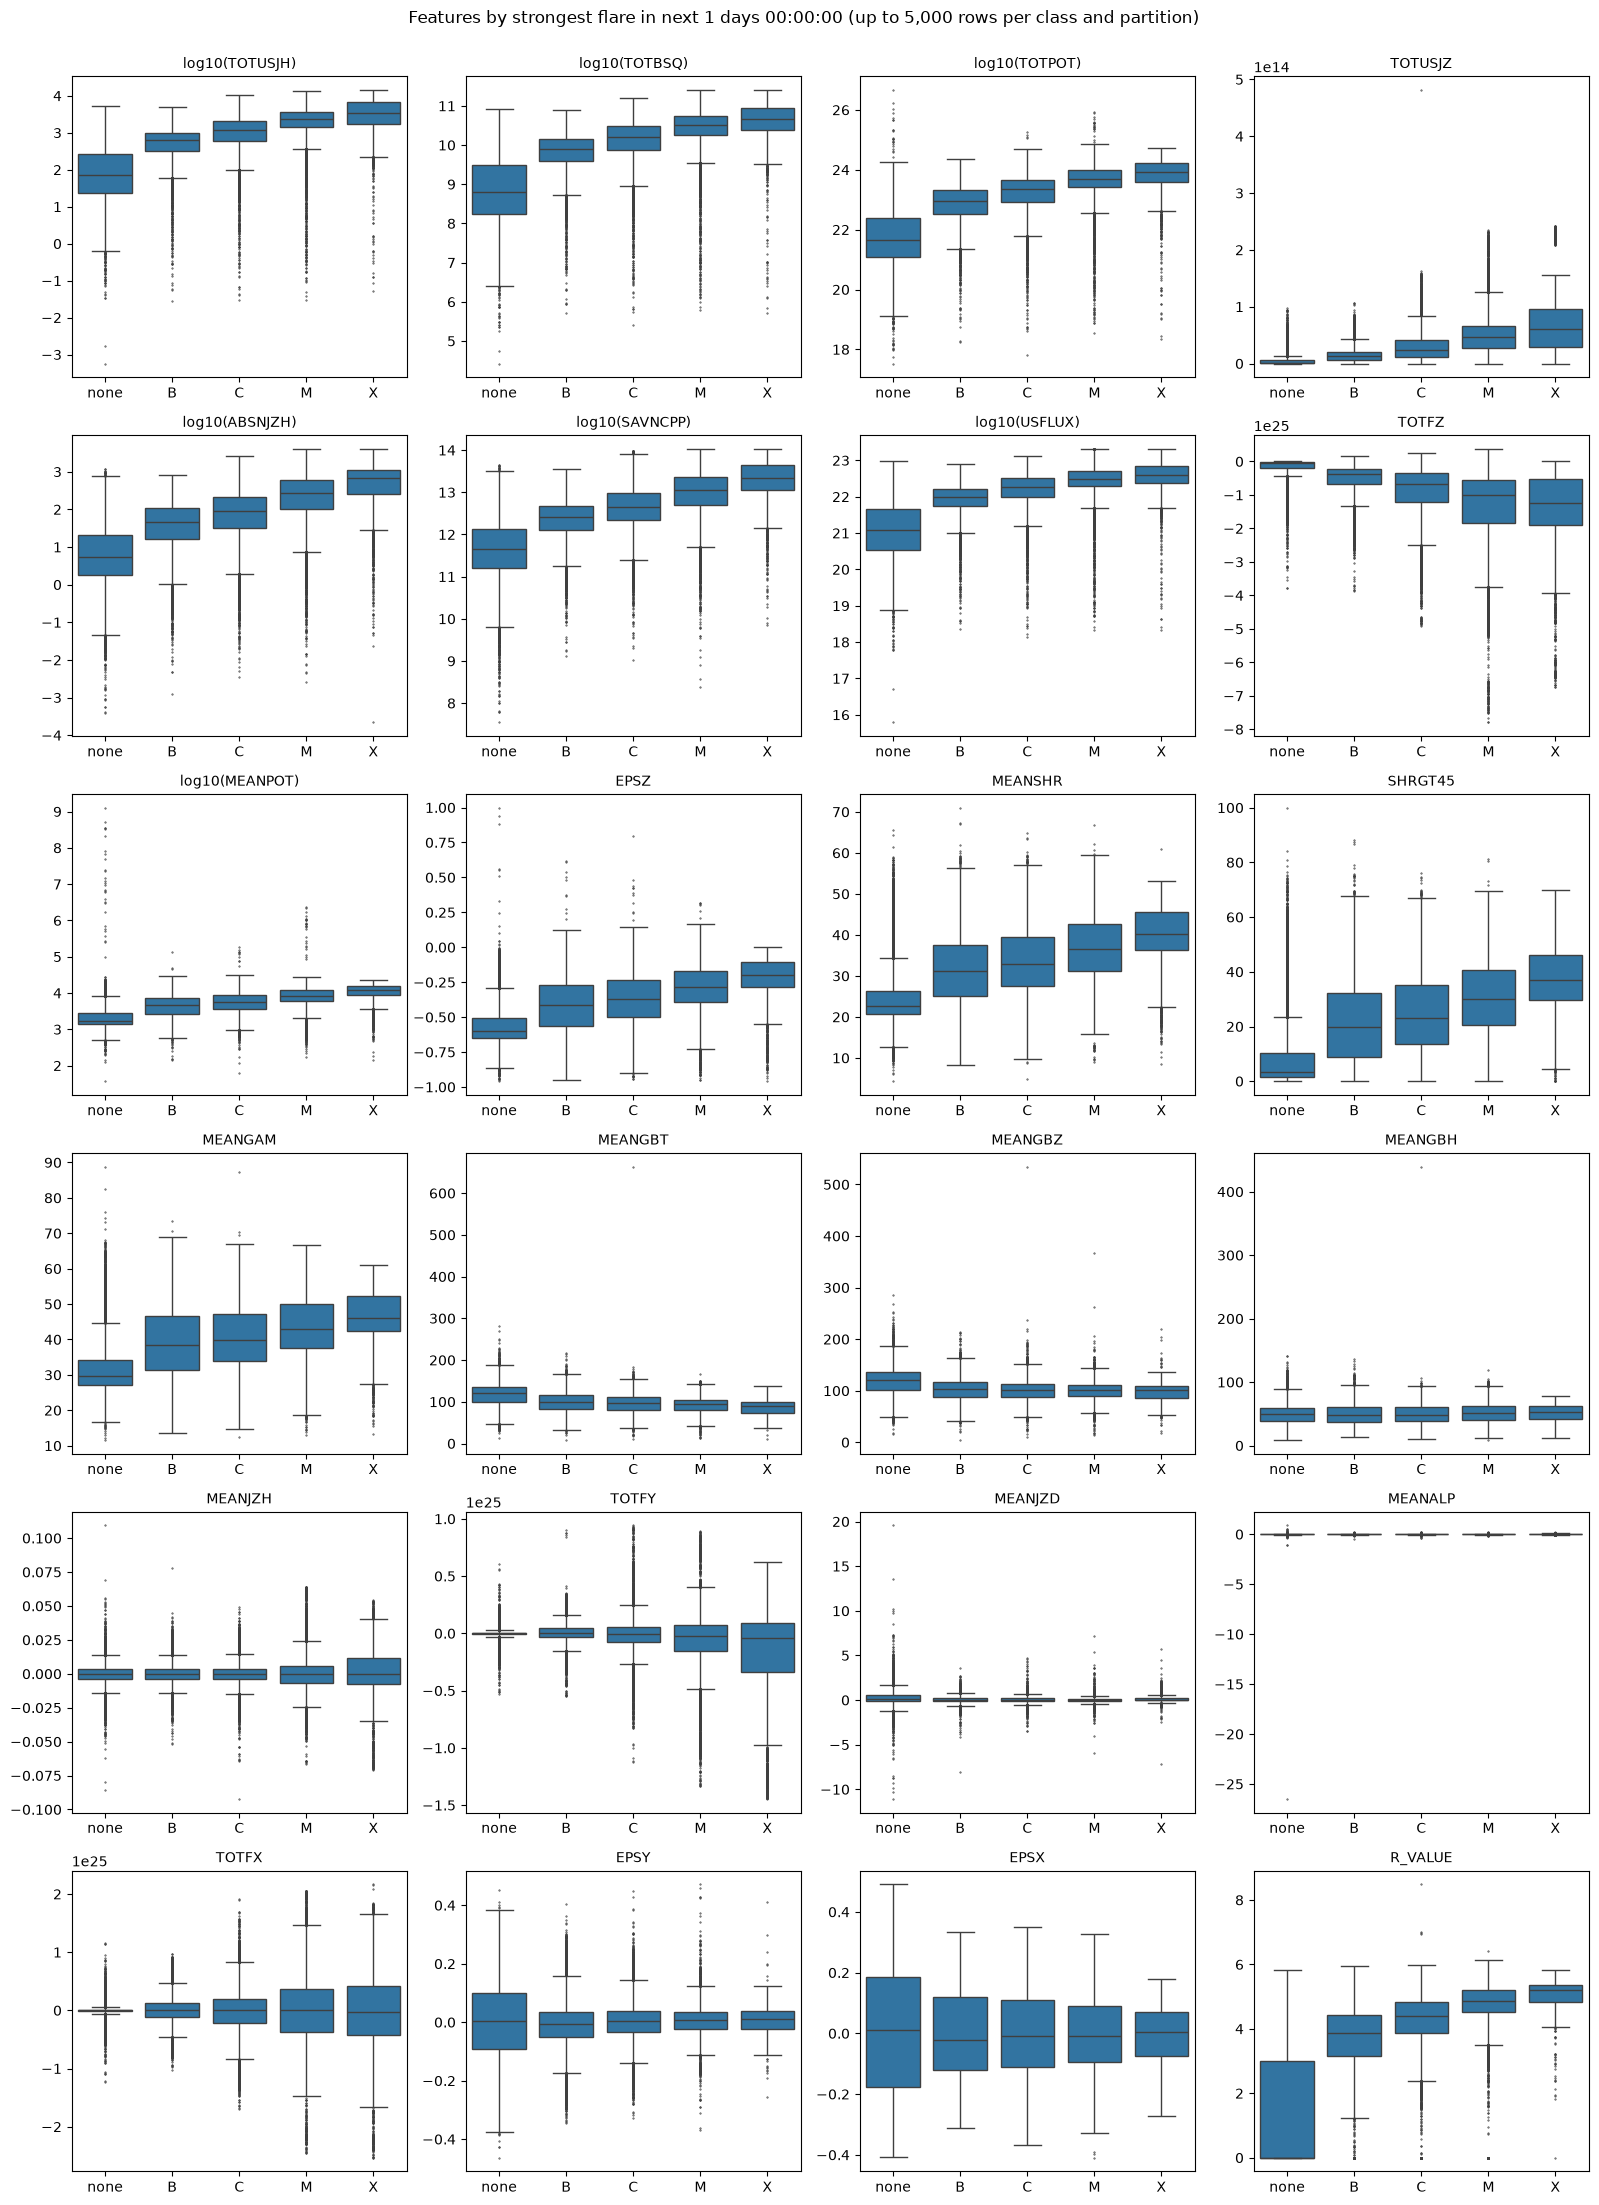

Rows per class in this sample:


next24
none    25000
B       24682
C       25000
M       25000
X        4674
Name: count, dtype: int64

In [20]:
# How each feature differs by target: strongest flare class in the next 24 h
fig, axes = plt.subplots(6, 4, figsize=(16, 22))
for ax, feat in zip(axes.flat, FEATURES):
    data = class_sample[[feat, 'next24']].copy()
    if feat in log_scale:
        data[feat] = np.log10(data[feat].clip(lower=data[feat][data[feat] > 0].min()))
    sns.boxplot(data=data, x='next24', y=feat, order=labels, ax=ax, fliersize=0.5)
    ax.set_title(f'log10({feat})' if feat in log_scale else feat, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.suptitle(f'Features by strongest flare in next {HORIZON} '
             f'(up to {SAMPLE_PER_CLASS:,} rows per class and partition)', y=1.0)
plt.tight_layout()
plt.show()

print('Rows per class in this sample:')
display(class_sample.next24.value_counts().reindex(labels))

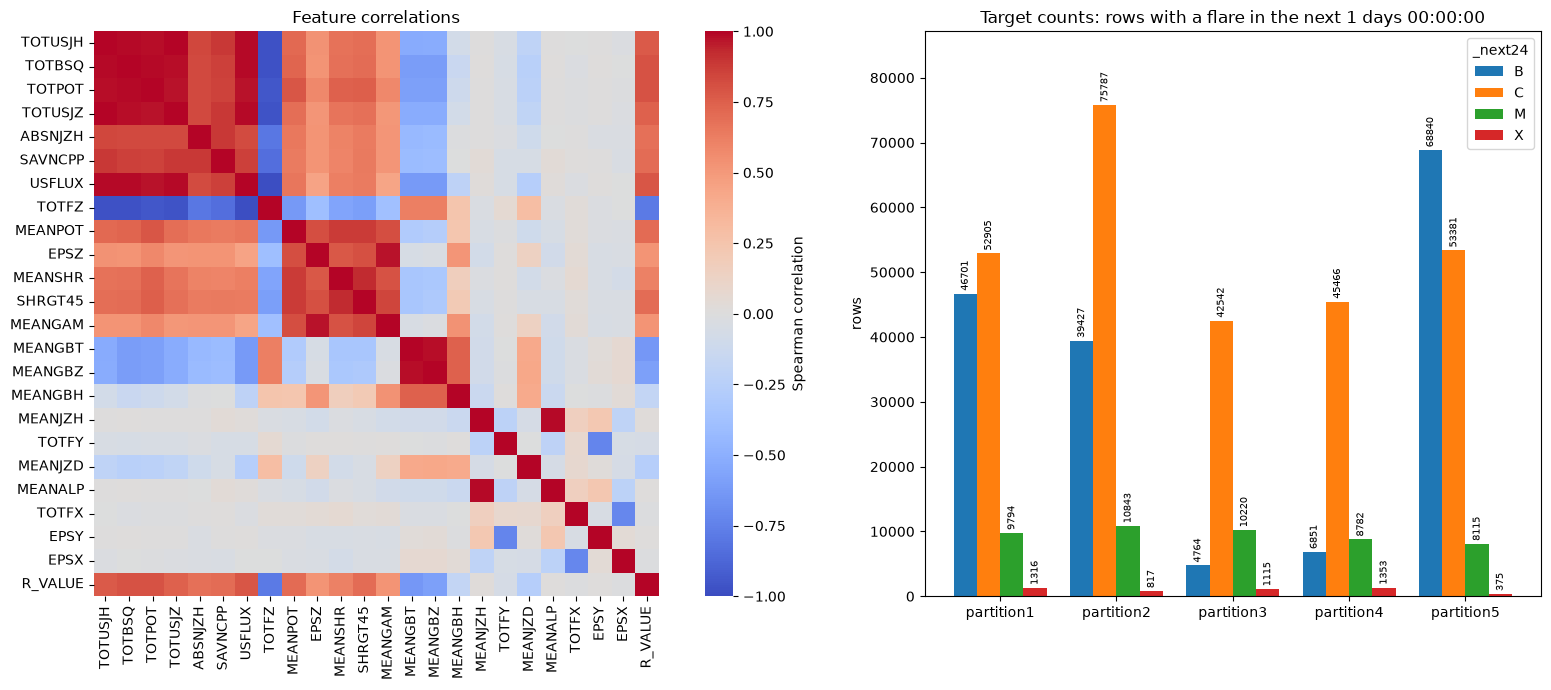

Highly correlated feature pairs (|rho| > 0.95):


rho
TOTUSJH TOTUSJZ  0.997380
TOTBSQ  USFLUX   0.992046
        TOTPOT   0.990235
USFLUX  TOTFZ   -0.989402
TOTUSJH TOTBSQ   0.988274
MEANJZH MEANALP  0.987725
TOTUSJH USFLUX   0.987159
TOTUSJZ USFLUX   0.985083
MEANGBT MEANGBZ  0.984301
TOTBSQ  TOTUSJZ  0.981821
TOTUSJH TOTPOT   0.978446
TOTBSQ  TOTFZ   -0.975345
TOTPOT  USFLUX   0.974060
        TOTUSJZ  0.972384
EPSZ    MEANGAM  0.970917
TOTUSJH TOTFZ   -0.970266
TOTUSJZ TOTFZ   -0.964924
TOTPOT  TOTFZ   -0.950515

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [3, 2]})
corr = uniform_sample[FEATURES].corr(method='spearman')
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, ax=axes[0],
            cbar_kws={'label': 'Spearman correlation'})
axes[0].set_title('Feature correlations')

window.drop(index='total')[CLASSES].plot.bar(ax=axes[1], width=0.8)
for container in axes[1].containers:
    axes[1].bar_label(container, fontsize=7, rotation=90, padding=2)
axes[1].set_title(f'Target counts: rows with a flare in the next {HORIZON}')
axes[1].set_ylabel('rows')
axes[1].tick_params(axis='x', rotation=0)
axes[1].margins(y=0.15)
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print('Highly correlated feature pairs (|rho| > 0.95):')
display(pairs[pairs.abs() > 0.95].sort_values(key=abs, ascending=False).rename('rho').to_frame())

## Summary

In [22]:
feature_missing = missing_df.loc[FEATURES]
summary = pd.DataFrame({
    'files': files.groupby('partition').size(),
    'rows': rows_per_part,
    'missing feature cells %': (feature_missing.sum() / (rows_per_part * len(FEATURES)) * 100).round(2),
    'rows with all features missing': row_missing_df.loc['rows with all features missing'],
    'duplicate rows': pd.DataFrame(dup_counts).loc[['identical rows within a file', 'identical rows across files']].sum(),
    'invalid values': invalid_df.sum(),
    'QUALITY-flagged rows': pd.Series(quality_flags),
    'timestamp issues': timeline[['bad_timestamps', 'dup_timestamps', 'non_monotonic_steps']].sum(axis=1),
    'off-cadence gaps': timeline['off_cadence_steps'],
    'median sequence rows': files.groupby('partition').rows.median(),
    'flare events (all classes)': totals.drop(index='total').sum(axis=1),
    '>=M in next 24 h %': (mx / window.sum(axis=1) * 100).drop(index='total').round(3),
})
display(summary)

,files,rows,missing feature cells %,rows with all features missing,duplicate rows,invalid values,QUALITY-flagged rows,timestamp issues,off-cadence gaps,median sequence rows,flare events (all classes),>=M in next 24 h %
partition1,805,585047,7.68,43451,18671,55075,31740,0,0,691.0,2818,1.899
partition2,1045,756600,10.96,69735,39144,67996,50061,0,0,677.0,3026,1.541
partition3,474,336575,8.40,27234,12493,33160,15590,0,0,625.0,1465,3.368
partition4,565,407795,7.72,30179,15564,35834,17703,0,0,683.0,1556,2.485
partition5,1209,793641,8.29,63694,25111,65423,223279,0,0,578.0,3743,1.070
